# **Preparing Dependancies**

In [1]:
!pip install -q diffusers transformers accelerate safetensors


# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [2]:
import gc
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from diffusers import (
    DDIMScheduler,
    DPMSolverMultistepScheduler,
    EulerAncestralDiscreteScheduler,
    StableDiffusionImg2ImgPipeline,
    StableDiffusionInpaintPipeline,
    StableDiffusionPipeline,
)
from PIL import Image, ImageDraw, ImageFilter, ImageOps
from transformers import pipeline as transformers_pipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
BASE_MODEL_ID = "runwayml/stable-diffusion-v1-5"
INPAINT_MODEL_ID = "runwayml/stable-diffusion-inpainting"

print(f"Using device: {DEVICE}")

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL_ID,
    torch_dtype=DTYPE,
    safety_checker=None,
    requires_safety_checker=False,
).to(DEVICE)

if DEVICE == "cuda":
    pipe.enable_attention_slicing()

print("Base Stable Diffusion pipeline is ready.")


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Base Stable Diffusion pipeline is ready.


## **Generate Image**

Running simple text-to-image generation with seed 222.


  0%|          | 0/50 [00:00<?, ?it/s]

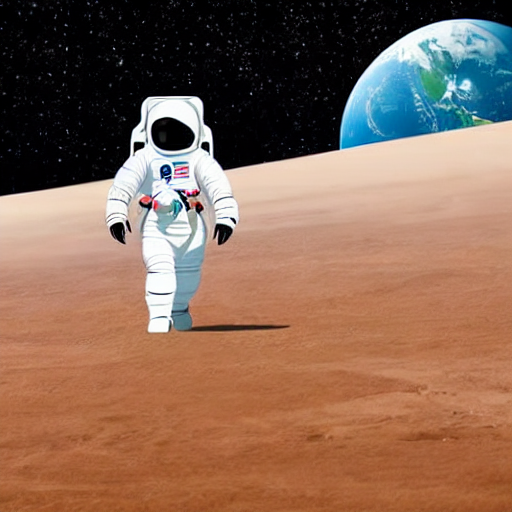

In [3]:
def build_generator(seed):
    return torch.Generator(device=DEVICE).manual_seed(int(seed))


def generate_simple_image(prompt, negative_prompt, seed):
    generator = build_generator(seed)
    print(f"Running simple text-to-image generation with seed {seed}.")

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
    )
    return result.images[0]


main_prompt = "an astronaut with full white spacesuit, standing on a flat moon plain, with earth in the background, minimal detail, 2D digital illustration"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed_value = 222

simple_image = generate_simple_image(
    prompt=main_prompt,
    negative_prompt=negative_prompt,
    seed=seed_value,
)

simple_image.save("simple_text_to_image.png")
simple_image


## **Generate Image with Hyperparameter Configuration**

Running advanced generation with seed=222, guidance_scale=10.0, steps=30.


  0%|          | 0/30 [00:00<?, ?it/s]

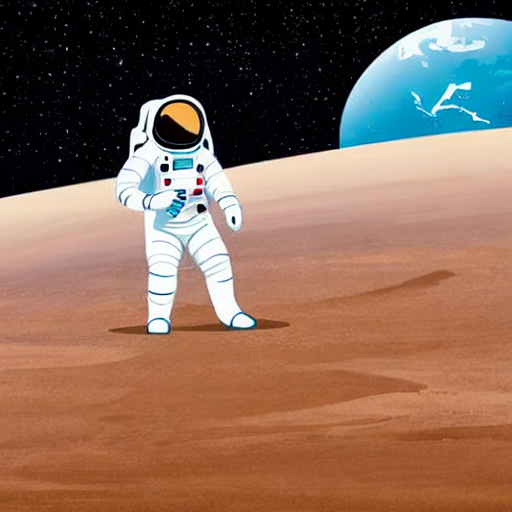

In [4]:
def generate_advanced_image(prompt, negative_prompt, seed, guidance_scale=10.0, num_inference_steps=30):
    generator = build_generator(seed)
    print(
        "Running advanced generation "
        f"with seed={seed}, guidance_scale={guidance_scale}, steps={num_inference_steps}."
    )
    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
        generator=generator,
    )
    return result.images[0]
advanced_image = generate_advanced_image(
    prompt=main_prompt,
    negative_prompt=negative_prompt,
    seed=seed_value,
    guidance_scale=10.0,
    num_inference_steps=30,
)
advanced_image.save("advanced_text_to_image.png")
advanced_image


## **Guidance Scale Comparison**

Comparing low and high guidance scale values.
Running advanced generation with seed=222, guidance_scale=5.5, steps=35.


  0%|          | 0/35 [00:00<?, ?it/s]

Running advanced generation with seed=222, guidance_scale=12.5, steps=35.


  0%|          | 0/35 [00:00<?, ?it/s]

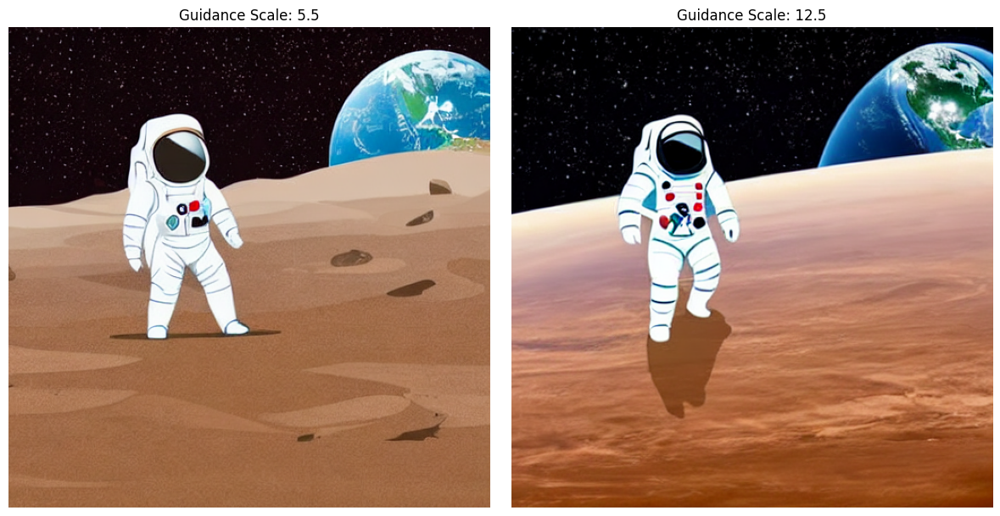

In [5]:
guidance_values = [5.5, 12.5]
fig, axes = plt.subplots(1, len(guidance_values), figsize=(12, 6))

print("Comparing low and high guidance scale values.")
for axis, guidance in zip(axes, guidance_values):
    image = generate_advanced_image(
        prompt=main_prompt,
        negative_prompt=negative_prompt,
        seed=seed_value,
        guidance_scale=guidance,
        num_inference_steps=35,
    )
    axis.imshow(image)
    axis.set_title(f"Guidance Scale: {guidance}")
    axis.axis("off")

plt.tight_layout()
plt.show()


### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah:**

    The lower guidance scale keeps the composition more flexible. The astronaut, moon surface, and Earth remain visible, but some small details may look looser because the model is not forced too strongly toward the prompt.

*   **Gambar dengan "Scale" Tinggi:**

    The higher guidance scale follows the prompt more aggressively. Important objects usually become clearer and more centered, although an overly high value can make edges harsher or reduce natural variation.


## **Inference Steps Comparison**

Comparing low and high inference step values.
Running advanced generation with seed=222, guidance_scale=8.5, steps=12.


  0%|          | 0/12 [00:00<?, ?it/s]

Running advanced generation with seed=222, guidance_scale=8.5, steps=45.


  0%|          | 0/45 [00:00<?, ?it/s]

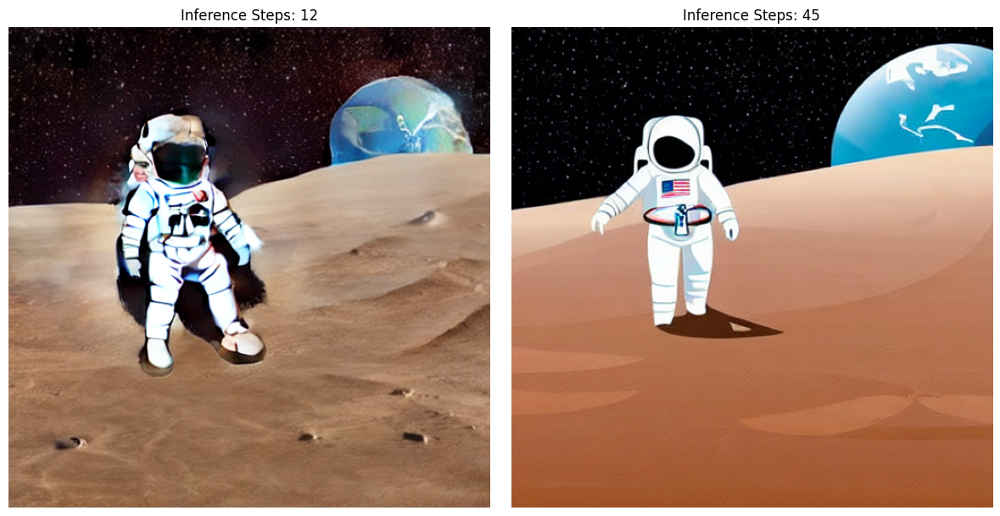

In [6]:
step_values = [12, 45]
fig, axes = plt.subplots(1, len(step_values), figsize=(12, 6))

print("Comparing low and high inference step values.")
for axis, steps in zip(axes, step_values):
    image = generate_advanced_image(
        prompt=main_prompt,
        negative_prompt=negative_prompt,
        seed=seed_value,
        guidance_scale=8.5,
        num_inference_steps=steps,
    )
    axis.imshow(image)
    axis.set_title(f"Inference Steps: {steps}")
    axis.axis("off")

plt.tight_layout()
plt.show()


### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah:**

    With fewer denoising steps, the image is produced faster but the shapes can be less refined. Fine details on the suit, moon texture, and Earth may look softer or slightly noisy.

*   **Gambar dengan "Step" Tinggi:**

    With more denoising steps, the image becomes more stable and polished. The subject boundaries, background, and lighting transitions usually become cleaner and more consistent.


## **Batch Inference from One Prompt**

Generating four images in one batch inference call.


  0%|          | 0/35 [00:00<?, ?it/s]

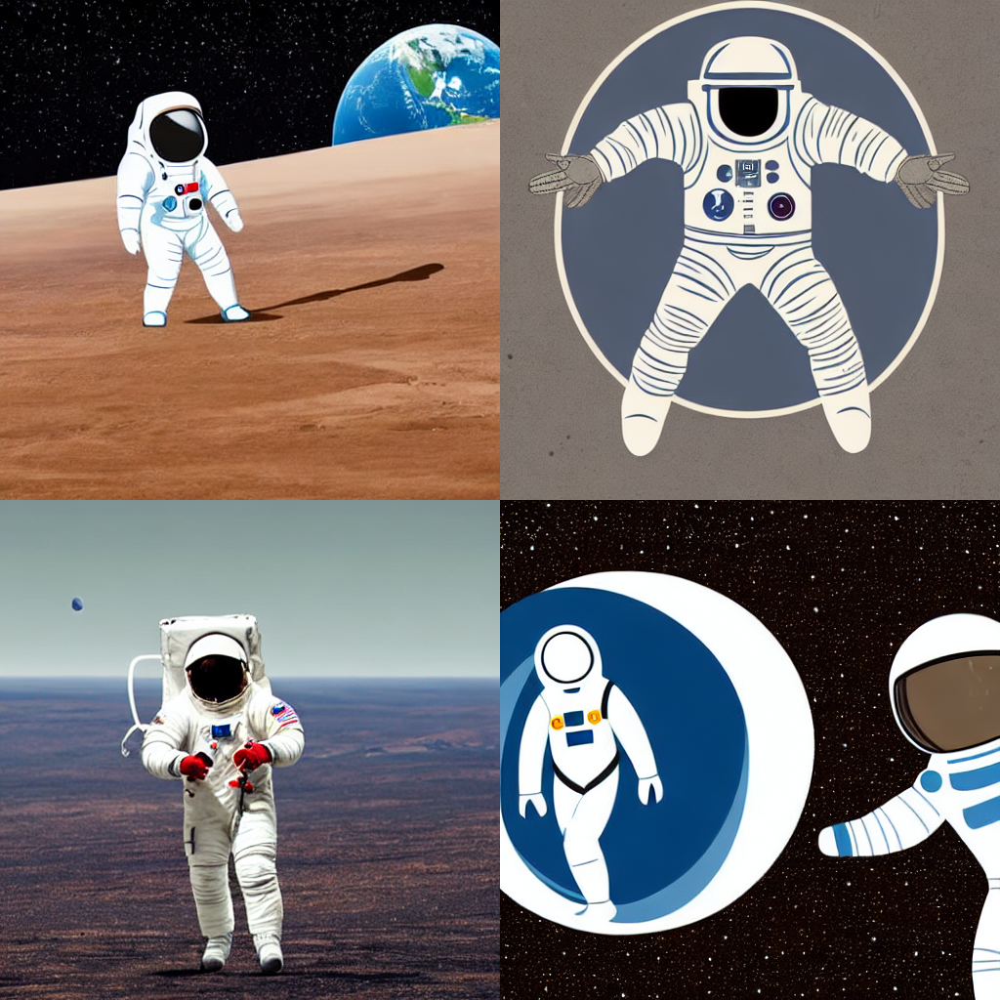

In [7]:
def make_image_grid(images, rows=2, cols=2):
    width, height = images[0].size
    grid = Image.new("RGB", (cols * width, rows * height), color=(255, 255, 255))
    for index, image in enumerate(images[: rows * cols]):
        x_pos = (index % cols) * width
        y_pos = (index // cols) * height
        grid.paste(image, (x_pos, y_pos))
    return grid


print("Generating four images in one batch inference call.")
batch_images = pipe(
    prompt=[main_prompt] * 4,
    negative_prompt=[negative_prompt] * 4,
    guidance_scale=8.0,
    num_inference_steps=35,
    generator=[build_generator(seed_value + offset) for offset in range(4)],
).images

batch_grid = make_image_grid(batch_images, rows=2, cols=2)
batch_grid.save("batch_grid_2x2.png")
batch_grid


## **Load Scheduler**

Generating scheduler comparison images.
Scheduler switched to Euler A.


  0%|          | 0/35 [00:00<?, ?it/s]

Scheduler switched to DPM++.


  0%|          | 0/35 [00:00<?, ?it/s]

Scheduler switched to DDIM.


  0%|          | 0/35 [00:00<?, ?it/s]

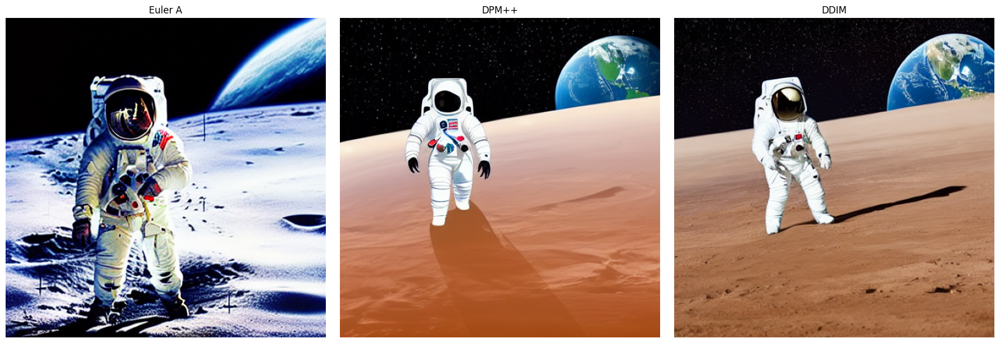

In [8]:
def load_scheduler(pipe, scheduler_name):
    scheduler_options = {
        "Euler A": EulerAncestralDiscreteScheduler,
        "DPM++": DPMSolverMultistepScheduler,
        "DDIM": DDIMScheduler,
    }
    if scheduler_name not in scheduler_options:
        raise ValueError(f"Unsupported scheduler: {scheduler_name}")

    scheduler_class = scheduler_options[scheduler_name]
    pipe.scheduler = scheduler_class.from_config(pipe.scheduler.config)
    print(f"Scheduler switched to {scheduler_name}.")
    return pipe


scheduler_names = ["Euler A", "DPM++", "DDIM"]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

print("Generating scheduler comparison images.")
for axis, scheduler_name in zip(axes, scheduler_names):
    load_scheduler(pipe, scheduler_name)
    image = pipe(
        prompt=main_prompt,
        negative_prompt=negative_prompt,
        guidance_scale=8.0,
        num_inference_steps=35,
        generator=build_generator(seed_value),
    ).images[0]
    axis.imshow(image)
    axis.set_title(scheduler_name)
    axis.axis("off")

plt.tight_layout()
plt.show()


### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**

    Euler A tends to produce expressive variation and slightly more dramatic texture. It is useful when a creative illustration result is preferred.

*   **Gambar dengan "DPM++ Scheduler":**

    DPM++ often gives a balanced result with cleaner structure and more stable details, especially when the prompt describes a clear subject.

*   **Gambar dengan "DDIM Scheduler":**

    DDIM usually produces a smoother and more controlled image. The result may look less random, which can be useful for repeatable comparisons.


# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Base + Refiner Image Generation**

Stage 1: generating latent output with the base pipeline.


  0%|          | 0/50 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Stage 2: refining the latent output with an image-to-image pipeline.


  0%|          | 0/40 [00:00<?, ?it/s]

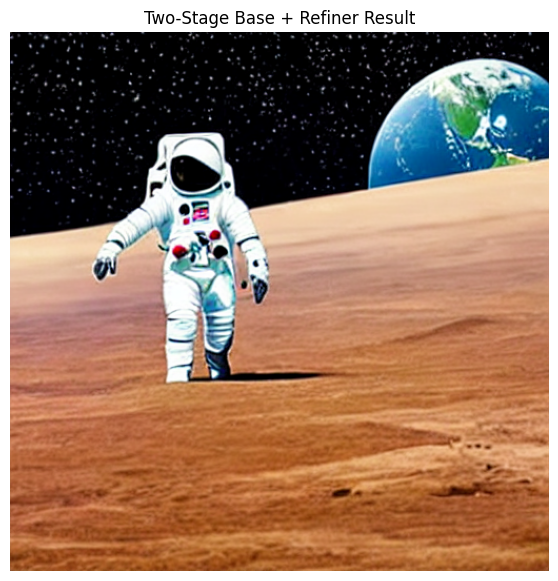

In [9]:
def run_two_stage_refiner(prompt, negative_prompt, seed=222, steps=50, split_point=0.8):
    print("Stage 1: generating latent output with the base pipeline.")
    latent_generator = build_generator(seed)
    latent_output = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        denoising_end=split_point,
        output_type="latent",
        generator=latent_generator,
    ).images

    print("Stage 2: refining the latent output with an image-to-image pipeline.")
    refiner_pipe = StableDiffusionImg2ImgPipeline(**pipe.components).to(DEVICE)
    if DEVICE == "cuda":
        refiner_pipe.enable_attention_slicing()

    refined = refiner_pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=latent_output,
        num_inference_steps=steps,
        denoising_start=split_point,
        generator=build_generator(seed),
    ).images[0]
    return refined


refined_image = run_two_stage_refiner(main_prompt, negative_prompt)
refined_image.save("two_stage_refined_image.png")

plt.figure(figsize=(7, 7))
plt.imshow(refined_image)
plt.title("Two-Stage Base + Refiner Result")
plt.axis("off")
plt.show()


## **Inpainting**

### **Load Model Inpainting**

In [10]:
print("Loading the dedicated Stable Diffusion inpainting pipeline.")
inpaint_pipe = StableDiffusionInpaintPipeline.from_pretrained(
    INPAINT_MODEL_ID,
    torch_dtype=DTYPE,
    safety_checker=None,
    requires_safety_checker=False,
).to(DEVICE)

if DEVICE == "cuda":
    inpaint_pipe.enable_attention_slicing()

print("Inpainting pipeline is ready.")


Loading the dedicated Stable Diffusion inpainting pipeline.


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Inpainting pipeline is ready.


### **Manual Masking**

Manual mask is prepared for the broken satellite area.


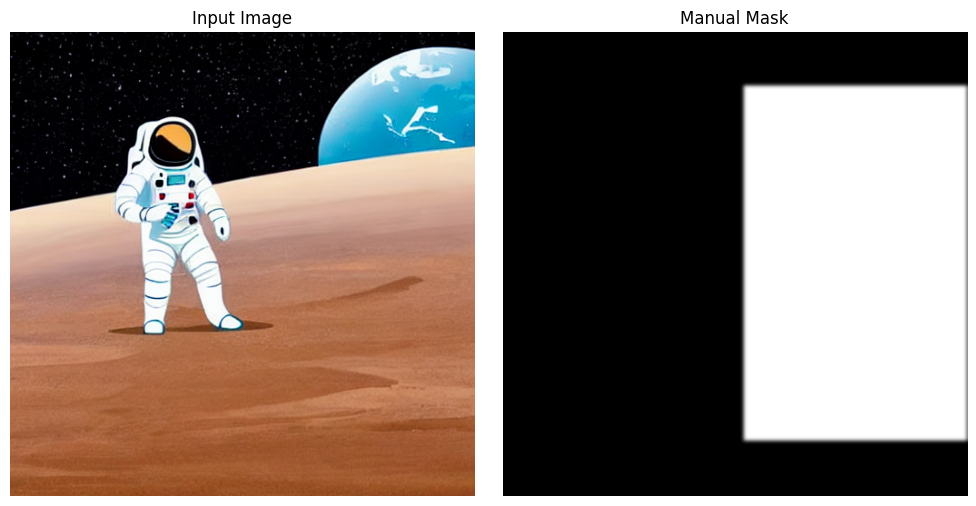

In [11]:
source_for_inpainting = advanced_image.copy().convert("RGB")
canvas_width, canvas_height = source_for_inpainting.size

manual_mask = Image.new("L", source_for_inpainting.size, 0)
mask_draw = ImageDraw.Draw(manual_mask)
mask_draw.rectangle((265, 60, 510, 450), fill=255)
manual_mask = manual_mask.filter(ImageFilter.GaussianBlur(radius=2))

print("Manual mask is prepared for the broken satellite area.")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(source_for_inpainting)
axes[0].set_title("Input Image")
axes[0].axis("off")
axes[1].imshow(manual_mask, cmap="gray")
axes[1].set_title("Manual Mask")
axes[1].axis("off")
plt.tight_layout()
plt.show()


### **Generate**

Running inpaint_engine with seed 9.


  0%|          | 0/47 [00:00<?, ?it/s]

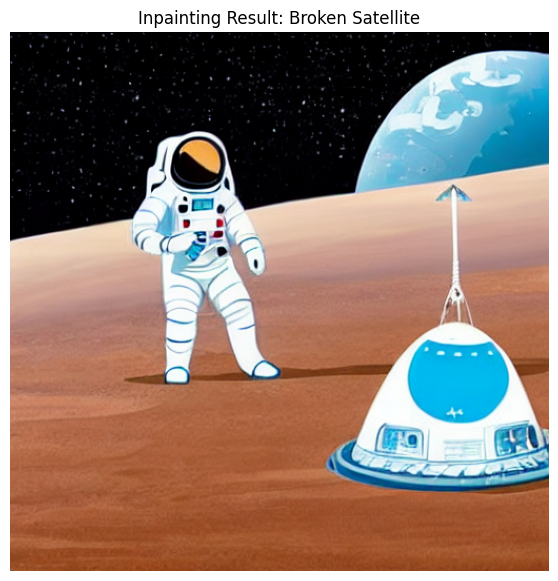

In [12]:
def inpaint_engine(image, mask, prompt):
    prepared_image = image.convert("RGB")
    prepared_mask = mask.convert("L").resize(prepared_image.size, resample=Image.NEAREST)
    print("Running inpaint_engine with seed 9.")

    result = inpaint_pipe(
        prompt=prompt,
        negative_prompt="blurry, low quality, flat object, clean sky, text, watermark",
        image=prepared_image,
        mask_image=prepared_mask,
        guidance_scale=8.5,
        strength=0.95,
        generator=build_generator(9),
    ).images[0]
    return result


satellite_prompt = "a crashed space satellite resting on the ground, gold-foiled boxy central body, bent rectangular solar panel wings, metallic antennas, detailed illustrative art style"

inpainted_satellite = inpaint_engine(
    image=source_for_inpainting,
    mask=manual_mask,
    prompt=satellite_prompt,
)
inpainted_satellite.save("inpainted_broken_satellite.png")

plt.figure(figsize=(7, 7))
plt.imshow(inpainted_satellite)
plt.title("Inpainting Result: Broken Satellite")
plt.axis("off")
plt.show()


## **Inpainting Menggunakan Automasking**

### **load Model Segmentation Untuk Masking**

In [13]:
print("Loading segmentation model for automatic masking.")
segmenter = transformers_pipeline(
    task="image-segmentation",
    model="facebook/detr-resnet-50-panoptic",
    device=0 if DEVICE == "cuda" else -1,
)
print("Segmentation model is ready.")


Loading segmentation model for automatic masking.


config.json:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/172M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/172M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/562 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

Segmentation model is ready.


### **Masking with Segmentation Model**

[transformers] `label_ids_to_fuse` unset. No instance will be fused.


Automatic mask is prepared for background enhancement.


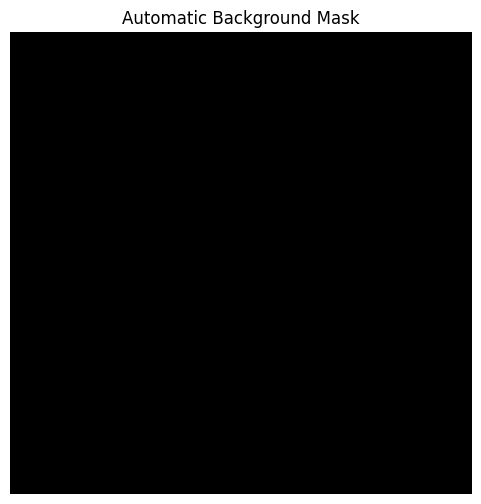

In [14]:
def build_space_background_mask(image):
    rgb_image = image.convert("RGB")
    detected_segments = segmenter(rgb_image)

    protected_subject = Image.new("L", rgb_image.size, 0)
    for segment in detected_segments:
        label = segment.get("label", "").lower()
        if label in {"person", "backpack", "helmet", "suit"}:
            segment_mask = segment["mask"].convert("L").resize(rgb_image.size)
            protected_subject = Image.fromarray(
                np.maximum(np.array(protected_subject), np.array(segment_mask)).astype(np.uint8)
            )

    grayscale = rgb_image.convert("L")
    dark_sky = grayscale.point(lambda value: 255 if value < 65 else 0)
    dark_sky = dark_sky.filter(ImageFilter.MaxFilter(9))
    dark_sky.paste(0, (0, 0), protected_subject.filter(ImageFilter.MaxFilter(13)))
    return dark_sky.filter(ImageFilter.GaussianBlur(radius=2))


auto_mask = build_space_background_mask(inpainted_satellite)
print("Automatic mask is prepared for background enhancement.")

plt.figure(figsize=(6, 6))
plt.imshow(auto_mask, cmap="gray")
plt.title("Automatic Background Mask")
plt.axis("off")
plt.show()


### **Generate**

Replacing the dark sky area with a richer galaxy background.


  0%|          | 0/47 [00:00<?, ?it/s]

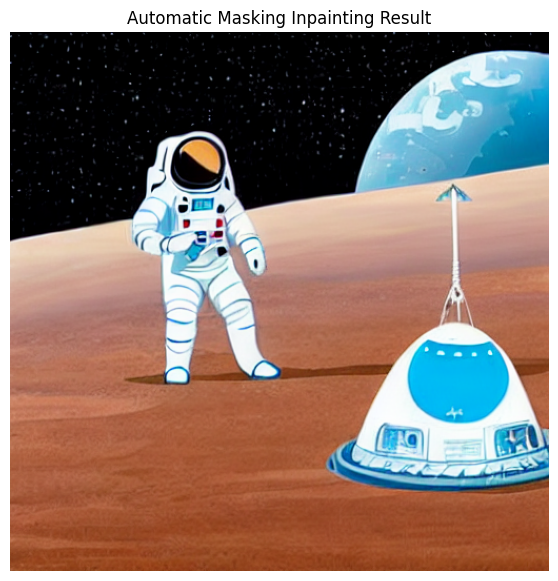

In [15]:
background_prompt = "glorious colorful space nebula galaxy, starry sky, detailed illustrative art style, masterpiece"
print("Replacing the dark sky area with a richer galaxy background.")

auto_inpaint_result = inpaint_pipe(
    prompt=background_prompt,
    negative_prompt="blurry, low quality, duplicate astronaut, text, watermark",
    image=inpainted_satellite.convert("RGB"),
    mask_image=auto_mask,
    guidance_scale=8.0,
    strength=0.95,
    generator=build_generator(222),
).images[0]

auto_inpaint_result.save("automatic_mask_background_result.png")

plt.figure(figsize=(7, 7))
plt.imshow(auto_inpaint_result)
plt.title("Automatic Masking Inpainting Result")
plt.axis("off")
plt.show()


## **Outpainting**

### **Prepare the Canvas**

One-side outpainting canvas and mask are ready.


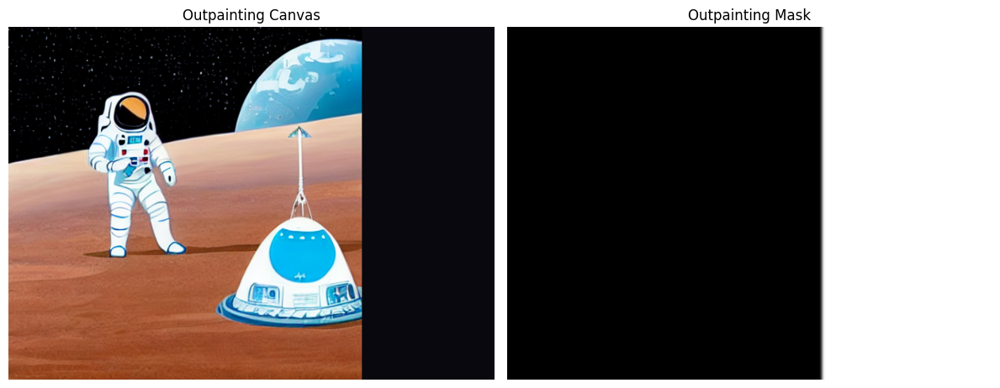

In [16]:
def prepare_outpainting(image, direction="right", expand_pixels=192, overlap=48):
    if direction not in {"left", "right", "up", "down"}:
        raise ValueError("direction must be one of: left, right, up, down")

    image = image.convert("RGB")
    width, height = image.size
    new_width, new_height = width, height
    paste_x, paste_y = 0, 0

    if direction in {"left", "right"}:
        new_width = width + expand_pixels
        paste_x = expand_pixels if direction == "left" else 0
    else:
        new_height = height + expand_pixels
        paste_y = expand_pixels if direction == "up" else 0

    new_width -= new_width % 8
    new_height -= new_height % 8

    base_canvas = Image.new("RGB", (new_width, new_height), (8, 8, 14))
    base_canvas.paste(image, (paste_x, paste_y))

    mask = Image.new("L", (new_width, new_height), 0)
    draw = ImageDraw.Draw(mask)
    if direction == "right":
        draw.rectangle((width - overlap, 0, new_width, new_height), fill=255)
    elif direction == "left":
        draw.rectangle((0, 0, expand_pixels + overlap, new_height), fill=255)
    elif direction == "down":
        draw.rectangle((0, height - overlap, new_width, new_height), fill=255)
    elif direction == "up":
        draw.rectangle((0, 0, new_width, expand_pixels + overlap), fill=255)

    return base_canvas, mask.filter(ImageFilter.GaussianBlur(radius=2))


outpaint_canvas, outpaint_mask = prepare_outpainting(
    auto_inpaint_result,
    direction="right",
    expand_pixels=192,
    overlap=56,
)

print("One-side outpainting canvas and mask are ready.")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(outpaint_canvas)
axes[0].set_title("Outpainting Canvas")
axes[0].axis("off")
axes[1].imshow(outpaint_mask, cmap="gray")
axes[1].set_title("Outpainting Mask")
axes[1].axis("off")
plt.tight_layout()
plt.show()


### **Generate**

Running one-side outpainting.


  0%|          | 0/50 [00:00<?, ?it/s]

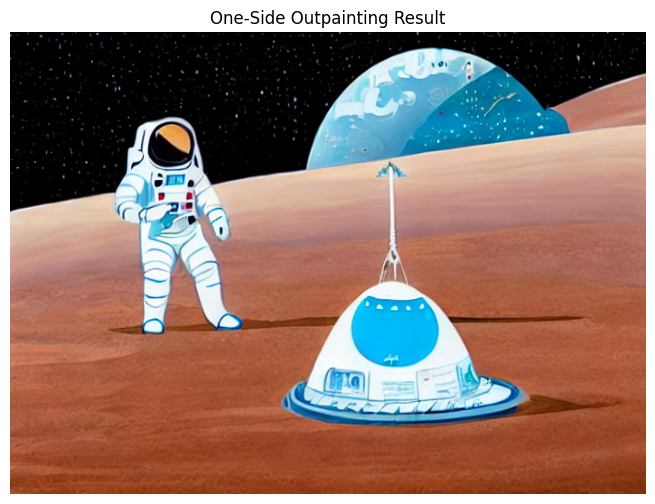

In [17]:
outpaint_prompt = "extended space nebula and distant stars, empty cosmic space, seamless cosmic background expansion, detailed illustrative art style"
print("Running one-side outpainting.")

outpainted_image = inpaint_pipe(
    prompt=outpaint_prompt,
    negative_prompt="border, frame, seam, blurry, astronaut, duplicate astronaut, human, person, clone, figure, low quality, text, watermark",
    image=outpaint_canvas,
    mask_image=outpaint_mask,
    width=outpaint_canvas.size[0],
    height=outpaint_canvas.size[1],
    guidance_scale=8.0,
    strength=1.0,
    generator=build_generator(222),
).images[0]

outpainted_image.save("one_side_outpainting_result.png")

plt.figure(figsize=(10, 6))
plt.imshow(outpainted_image)
plt.title("One-Side Outpainting Result")
plt.axis("off")
plt.show()


## **Outpainting Zoom Out**

### **Prepare Canvas for Zoom Out**

Zoom-out canvas and mask are ready.


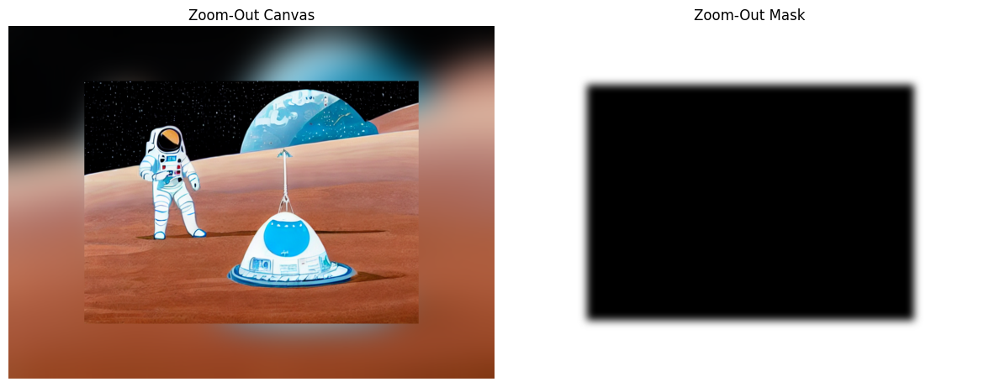

In [18]:
def prepare_zoom_out_canvas(image, scale=1.45, protected_margin=8, blur_radius=8):
    image = image.convert("RGB")
    width, height = image.size
    new_width = int(math.ceil(width * scale / 8) * 8)
    new_height = int(math.ceil(height * scale / 8) * 8)

    blurred_background = image.resize((new_width, new_height), resample=Image.BICUBIC)
    blurred_background = blurred_background.filter(ImageFilter.GaussianBlur(radius=35))

    paste_x = (new_width - width) // 2
    paste_y = (new_height - height) // 2
    blurred_background.paste(image, (paste_x, paste_y))

    zoom_mask = Image.new("L", (new_width, new_height), 255)
    draw = ImageDraw.Draw(zoom_mask)
    draw.rectangle(
        (
            paste_x + protected_margin,
            paste_y + protected_margin,
            paste_x + width - protected_margin,
            paste_y + height - protected_margin,
        ),
        fill=0,
    )
    return blurred_background, zoom_mask.filter(ImageFilter.GaussianBlur(radius=blur_radius))


zoom_canvas, zoom_mask = prepare_zoom_out_canvas(outpainted_image, scale=1.45)
print("Zoom-out canvas and mask are ready.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(zoom_canvas)
axes[0].set_title("Zoom-Out Canvas")
axes[0].axis("off")
axes[1].imshow(zoom_mask, cmap="gray")
axes[1].set_title("Zoom-Out Mask")
axes[1].axis("off")
plt.tight_layout()
plt.show()


### **Generate**

Running zoom-out outpainting.


  0%|          | 0/50 [00:00<?, ?it/s]

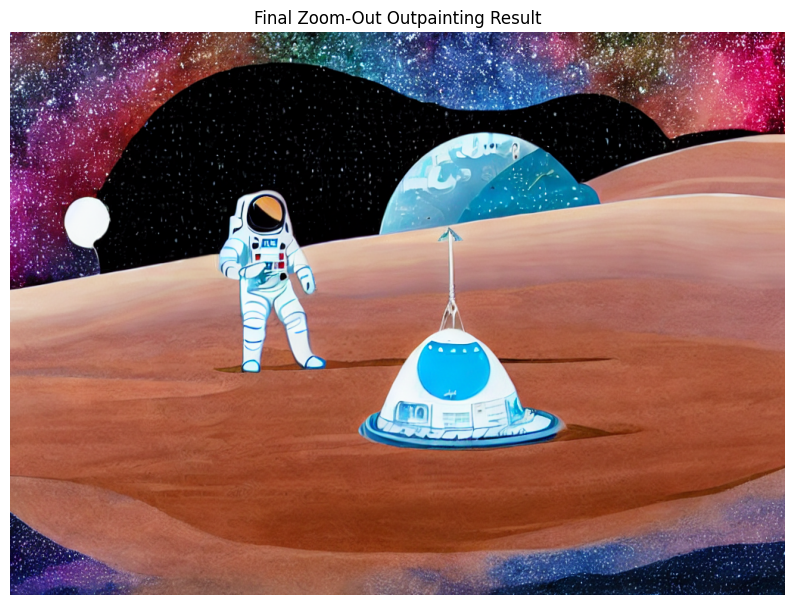

In [19]:
zoom_prompt = "vast space cosmic background with distant stars and colorful nebula, detailed illustrative art style"
print("Running zoom-out outpainting.")

final_zoom_result = inpaint_pipe(
    prompt=zoom_prompt,
    negative_prompt="astronaut, duplicate astronaut, extra person, human, person, clone, figure, bad anatomy, border, frame, text, watermark, blurry",
    image=zoom_canvas,
    mask_image=zoom_mask,
    width=zoom_canvas.size[0],
    height=zoom_canvas.size[1],
    guidance_scale=8.0,
    strength=1.0,
    generator=build_generator(222),
).images[0]

final_zoom_result.save("final_zoom_out_result.png")

plt.figure(figsize=(10, 8))
plt.imshow(final_zoom_result)
plt.title("Final Zoom-Out Outpainting Result")
plt.axis("off")
plt.show()
